<a href="https://colab.research.google.com/github/kjmobile/lb2/blob/main/11_PCA_Airline_Markets_all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 11. Principal Component Analysis: Five Numbers, Two Axes

Each market in our data is described by five numbers. Several of them move together: long markets have high fares,
for example. **Principal component analysis (PCA)** finds new axes, the **principal components**, that pack as much of
the spread (variance) as possible into as few axes as possible. With two components we can draw all 200 markets on
one flat picture.

Slides: W3.1, PCA (projection, eigenvalues and eigenvectors, principal components).

> **Data.** The 200 busiest U.S. domestic markets in 2019 (both directions combined), read straight from the course
> GitHub repository. Source: Sabre Market Intelligence, licensed to Embry-Riddle.

> **Full version.** This notebook includes the code that draws every figure. The `_simple` version leaves that code out and shows the same figures as pictures.

## 1. Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

routes = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/sabre_routes_2019.csv')
routes['market'] = routes['airport_1'] + '-' + routes['airport_2']
numbers = ['distance_mi', 'passengers', 'avg_fare', 'lcc_share', 'hhi']
routes[numbers].describe().round(2)

,distance_mi,passengers,avg_fare,lcc_share,hhi
count,200.00,200.00,200.00,200.00,200.00
mean,1092.74,917152.72,169.47,0.38,0.42
std,649.36,380820.37,63.17,0.29,0.16
min,100.00,555362.00,71.86,0.00,0.18
25%,606.00,636050.00,131.30,0.15,0.31
50%,972.00,809723.00,156.05,0.33,0.38
75%,1402.00,1081009.50,194.61,0.56,0.49
max,2697.00,3115042.00,430.98,1.00,1.00


| Column | Meaning |
|---|---|
| `airport_1`, `airport_2` | the two airports of the market |
| `distance_mi` | distance in miles |
| `passengers` | passengers in 2019 |
| `avg_fare` | average base fare ($) |
| `lcc_share` | share of passengers on low-cost airlines (0 to 1) |
| `hhi` | market concentration, the Herfindahl-Hirschman Index: square each airline's share and add them up (1 = one airline carries everyone) |
| `top_airline` | the airline with the most passengers: AA American, DL Delta, UA United, WN Southwest, AS Alaska, B6 JetBlue, HA Hawaiian, NK Spirit |

## 2. Some Inputs Say the Same Thing

A **correlation** near 1 or -1 means two columns move together; near 0 means they do not.

In [2]:
routes[numbers].corr().round(2)

,distance_mi,passengers,avg_fare,lcc_share,hhi
distance_mi,1.00,0.00,0.81,-0.33,-0.20
passengers,0.00,1.00,0.03,-0.13,-0.23
avg_fare,0.81,0.03,1.00,-0.50,-0.03
lcc_share,-0.33,-0.13,-0.50,1.00,0.11
hhi,-0.20,-0.23,-0.03,0.11,1.00


Distance and fare are strongly correlated (0.81): they carry much of the same information. PCA will combine them.

## 3. Standardize, Then Fit PCA

As with KNN and K-means, standardize first, so passengers (in the millions) do not dominate shares (0 to 1).

In [3]:
scaled = StandardScaler().fit_transform(routes[numbers])

pca = PCA()
pca.fit(scaled)
print('share of variance explained:', pca.explained_variance_ratio_.round(3))
print('cumulative:                 ', pca.explained_variance_ratio_.cumsum().round(3))

share of variance explained: [0.432 0.243 0.165 0.131 0.029]
cumulative:                  [0.432 0.676 0.84  0.971 1.   ]


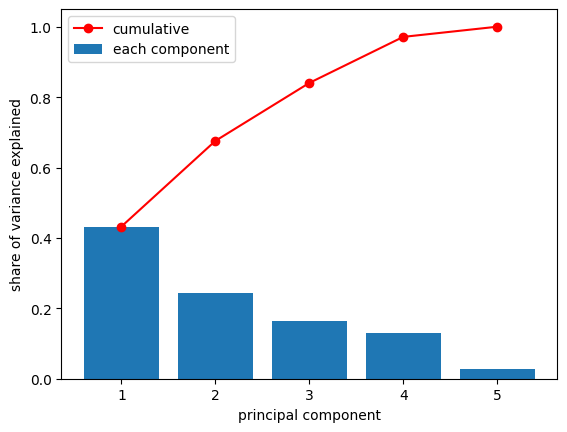

In [4]:
# Figure 1
k = np.arange(1, 6)
plt.bar(k, pca.explained_variance_ratio_, label='each component')
plt.plot(k, pca.explained_variance_ratio_.cumsum(), marker='o', color='red', label='cumulative')
plt.xlabel('principal component')
plt.ylabel('share of variance explained')
plt.legend()
plt.show()

The first component alone holds 43% of the spread in the five numbers; the first two hold 68%.

### Where the numbers come from: eigenvalues

PCA solves the eigenvalue equation $A v = \lambda v$ for the **covariance matrix** $A$ of the scaled data. Each
eigenvector $v$ is a component's direction; its eigenvalue $\lambda$ is the variance along that direction.
NumPy gives the same values directly:

In [5]:
eigenvalues = np.linalg.eigvalsh(np.cov(scaled.T))      # eigenvalues of the covariance matrix
print('eigenvalues (largest first):', np.sort(eigenvalues)[::-1].round(3))
print('PCA explained variance:     ', pca.explained_variance_.round(3))

eigenvalues (largest first): [2.172 1.223 0.827 0.658 0.145]
PCA explained variance:      [2.172 1.223 0.827 0.658 0.145]


## 4. What Does Each Component Mean? Loadings

Each component is a weighted sum of the five scaled inputs. The weights (**loadings**) tell us what it measures.

In [6]:
loadings = pd.DataFrame(pca.components_[:2].T, index=numbers, columns=['PC1', 'PC2']).round(2)
loadings

,PC1,PC2
distance_mi,0.59,-0.14
passengers,0.10,0.71
avg_fare,0.62,-0.22
lcc_share,-0.47,-0.06
hhi,-0.18,-0.65


- **PC1** is high for long, expensive markets with few low-cost passengers (distance +0.59, fare +0.62,
  low-cost share -0.47). Call it *"long and pricey"*.
- **PC2** is high for big markets with many competitors (passengers +0.71, concentration -0.65). Call it
  *"big and competitive"*.

## 5. All 200 Markets on One Picture

In [7]:
scores = pca.transform(scaled)          # each market's position on the new axes
routes['PC1'] = scores[:, 0]
routes['PC2'] = scores[:, 1]
routes[['market', 'PC1', 'PC2']].head().round(2)

,market,PC1,PC2
0,JFK-LAX,3.91,3.83
1,LGA-ORD,0.80,3.80
2,LAX-SFO,-0.44,3.84
3,LAX-ORD,1.51,1.97
4,LAS-LAX,-1.31,3.19


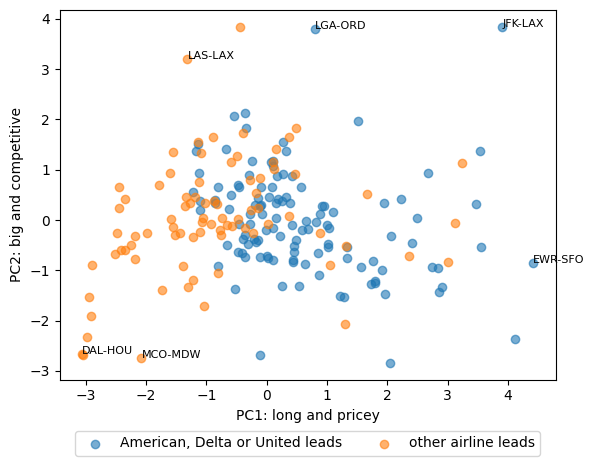

In [8]:
# Figure 2
hub = routes['top_airline'].isin(['AA', 'DL', 'UA'])
plt.scatter(routes.loc[hub, 'PC1'], routes.loc[hub, 'PC2'], alpha=0.6, label='American, Delta or United leads')
plt.scatter(routes.loc[~hub, 'PC1'], routes.loc[~hub, 'PC2'], alpha=0.6, label='other airline leads')
for name in ['JFK-LAX', 'EWR-SFO', 'DAL-HOU', 'LAS-LAX', 'MCO-MDW', 'LGA-ORD']:
    row = routes[routes['market'] == name].iloc[0]
    plt.annotate(name, (row['PC1'], row['PC2']), fontsize=8)
plt.xlabel('PC1: long and pricey')
plt.ylabel('PC2: big and competitive')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.show()

Check the meaning against the markets at each end:

In [9]:
cols = ['market', 'distance_mi', 'avg_fare', 'lcc_share', 'top_airline', 'PC1']
print(routes.sort_values('PC1')[cols].head(3).round(2), '\n')     # lowest PC1
print(routes.sort_values('PC1')[cols].tail(3).round(2))             # highest PC1

      market  distance_mi  avg_fare  lcc_share top_airline   PC1
180  DAL-HOU        240.0    115.68        1.0          WN -3.06
189  BUR-SMF        359.0    105.50        1.0          WN -3.04
119  OAK-SAN        447.0     98.67        1.0          WN -2.98 

      market  distance_mi  avg_fare  lcc_share top_airline   PC1
0    JFK-LAX       2470.0    349.29       0.32          DL  3.91
139  IAD-SFO       2413.0    430.98       0.01          UA  4.12
11   EWR-SFO       2559.0    428.33       0.00          UA  4.42


In [10]:
cols = ['market', 'passengers', 'hhi', 'PC2']
print(routes.sort_values('PC2')[cols].head(3).round(2), '\n')     # lowest PC2
print(routes.sort_values('PC2')[cols].tail(3).round(2))             # highest PC2

      market  passengers   hhi   PC2
155  LAX-MIA    627876.0  0.88 -2.84
165  MCO-MDW    604583.0  0.97 -2.74
190  DCA-MIA    563216.0  0.95 -2.69 

    market  passengers   hhi   PC2
1  LGA-ORD   2600397.0  0.29  3.80
0  JFK-LAX   3115042.0  0.27  3.83
2  LAX-SFO   2289910.0  0.21  3.84


Short Southwest markets in Texas and California sit at the low end of PC1; transcontinental markets, mostly led by
United, at the high end. The busiest markets (JFK-LAX, LAX-SFO, LGA-ORD) top PC2, while markets that one airline nearly owns sit at the
bottom.

### Your turn

How many components do we need to keep at least **80%** of the variance?

1. In the cell below, fill in the blanks (`___`) and run it.
2. Then finish this sentence:
   *We need ___ components, which together explain ___ of the variance.*

<details><summary>Show answer</summary>

```python
cumulative = pca.explained_variance_ratio_.cumsum()
print(cumulative.round(3))
print('components needed for 80%:', np.argmax(cumulative >= 0.8) + 1)
```

*We need **3** components, which together explain **0.84** of the variance.*
</details>

In [ ]:
cumulative = pca.explained_variance_ratio_.___()
print(cumulative.round(3))
print('components needed for 80%:', np.argmax(cumulative >= ___) + 1)

## 6. Summary

| Step | What we found |
|---|---|
| Why | Several inputs move together (distance and fare: correlation 0.81) |
| Standardize | So passengers in millions do not drown out shares |
| Explained variance | PC1 43%, PC2 24%: two axes hold about two-thirds of the spread |
| Eigenvalues | The variance of each component = an eigenvalue of the covariance matrix |
| Meaning | PC1 = long and pricey; PC2 = big and competitive |

---
# Challenge

1. Run PCA **without** standardizing (`PCA().fit(routes[numbers])`). What share does PC1 explain now, and which
   input does it follow? Why?
2. Use the two components as inputs to K-means (notebook 10) with 3 clusters. Do you get similar groups?
3. Name PC3 by reading its loadings (`pca.components_[2]`).

In [12]:
# Your answer